# Reto avanzado 1 · Comparativa de algoritmos de clustering

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Comparamos el K-Means del Reto 3 (k = 6) con otros algoritmos, **con el mismo k y los mismos datos preparados**
(las 12 features del pipeline del Reto 2):

| Algoritmo | Idea | Por qué lo incluimos |
|---|---|---|
| **Gaussian Mixture (GMM)** | Cada cluster es una "campana" (distribución normal) con su propia forma y tamaño; asignación probabilística | Generaliza K-Means: permite clusters alargados y de distinto tamaño |
| **Aglomerativo (jerárquico)** | Une progresivamente los clientes más parecidos hasta formar k grupos | No asume forma de los clusters; enfoque totalmente distinto |
| **DBSCAN** | Busca zonas densas separadas por zonas vacías | Detecta formas arbitrarias y ruido. **No admite fijar k** (ver apartado 5) |

Para cada uno: métricas comparables, estabilidad, coste computacional y, sobre todo, **si los segmentos cambian**.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

from features import (cargar_datos, construir_pipeline, ajustar_kmeans, nombrar_segmentos, K_FINAL, SEMILLA,
                      N_INIT_FINAL, ORDEN_SEGMENTOS, COLORES_SEGMENTOS)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

df = cargar_datos()
X = construir_pipeline().fit_transform(df)
Xv = X.to_numpy()
t = time.time()
km = ajustar_kmeans(X)
tiempo_km = time.time() - t
nombres_km = nombrar_segmentos(pd.DataFrame(km.cluster_centers_, columns=X.columns))
seg_km = pd.Categorical(pd.Series(km.labels_).map(nombres_km), categories=ORDEN_SEGMENTOS)
print("Matriz:", X.shape, f"· K-Means (n_init={N_INIT_FINAL}) en {tiempo_km:.0f} s")

Matriz: (173456, 12) · K-Means (n_init=50) en 5 s


## 1. Cómo se compara (y trampas que evitamos)

**Muestra común de evaluación.** El silhouette exige comparar cada cliente con todos los demás (inviable con 173.456)
y el algoritmo aglomerativo no cabe en memoria con todos los clientes (apartado 4). Todas las métricas se calculan
sobre **la misma muestra aleatoria de 20.000 clientes**, para que la comparación sea justa.

**Tres métricas, porque ninguna es perfecta:**

| Métrica | Qué mide | Mejor si |
|---|---|---|
| **Silhouette** | Cohesión frente a separación de cada cliente | Más alto (máx. 1) |
| **Calinski-Harabasz** | Dispersión entre clusters / dispersión dentro de ellos | Más alto |
| **Davies-Bouldin** | Parecido medio de cada cluster con su vecino más similar | Más bajo (mín. 0) |

⚠️ Las tres usan **distancias euclídeas** y premian clusters compactos y redondeados, que es justo lo que busca K-Means.
Tienen un **sesgo a favor de K-Means**; por eso no basta con mirar la métrica.

**Una métrica alta no garantiza una buena segmentación.** Añadimos el **tamaño del cluster más grande**: una
"segmentación" que mete al 90 % de los clientes en un grupo puede puntuar bien y no servir para nada (apartado 4).

In [2]:
rng = np.random.default_rng(0)
idx = rng.choice(len(X), 20_000, replace=False)
Xs = Xv[idx]

def evaluar(etiquetas, nombre, segundos, notas=""):
    l = np.asarray(etiquetas)
    l_m = l[idx] if len(l) == len(X) else l
    validos = l_m >= 0                                  # DBSCAN marca el ruido con -1
    tam = np.bincount(l[l >= 0]) / len(l) * 100
    return {"algoritmo": nombre,
            "nº clusters": len(tam),
            "silhouette": silhouette_score(Xs[validos], l_m[validos]),
            "Calinski-Harabasz": calinski_harabasz_score(Xs[validos], l_m[validos]),
            "Davies-Bouldin": davies_bouldin_score(Xs[validos], l_m[validos]),
            "cluster más grande (%)": tam.max(),
            "cluster más pequeño (%)": tam.min(),
            "tiempo (s)": segundos,
            "notas": notas}

resultados = [evaluar(km.labels_, "K-Means", tiempo_km, f"n_init={N_INIT_FINAL}, todos los clientes")]
pd.DataFrame(resultados)

,algoritmo,nº clusters,silhouette,Calinski-Harabasz,Davies-Bouldin,cluster más grande (%),cluster más pequeño (%),tiempo (s),notas
0,K-Means,6,0.136,"2,205.665",1.892,27.067,8.747,5.078,"n_init=50, todos los clientes"


## 2. Gaussian Mixture Models (GMM)

### 2.1 Configuración estándar

In [3]:
t = time.time()
gmm = GaussianMixture(n_components=K_FINAL, covariance_type="full", n_init=3, random_state=SEMILLA).fit(X)
tiempo_gmm = time.time() - t
lab_gmm = gmm.predict(X)
prob_gmm = gmm.predict_proba(X).max(axis=1)
resultados.append(evaluar(lab_gmm, "GMM (estándar)", tiempo_gmm, "covarianza completa, reg_covar=1e-6"))
print(f"Convergió: {gmm.converged_}")
pd.Series({"% clientes con probabilidad máxima > 0,9": (prob_gmm > .9).mean() * 100,
           "% clientes con probabilidad máxima < 0,6": (prob_gmm < .6).mean() * 100}).round(1)

Convergió: True


% clientes con probabilidad máxima > 0,9   100.000
% clientes con probabilidad máxima < 0,6     0.000
dtype: float64

**Detalle sospechoso:** GMM asigna a **todos** los clientes a su cluster con probabilidad > 0,9. La gracia de GMM es
dar probabilidades (un cliente puede estar 60 % en un grupo y 40 % en otro). En datos donde ya vimos que los clusters
se solapan (Reto 3), una certeza del 100 % no es creíble. Miramos las varianzas de cada componente:

In [4]:
gmm_diag = GaussianMixture(n_components=K_FINAL, covariance_type="diag", n_init=3, random_state=SEMILLA).fit(X)
varianzas = pd.DataFrame(gmm_diag.covariances_, columns=X.columns).T
varianzas.columns = [f"comp. {i} ({w:.0%})" for i, w in enumerate(gmm_diag.weights_)]
display(varianzas.round(4))
print("Valores distintos por feature:", X.nunique().to_dict())

,comp. 0 (45%),comp. 1 (9%),comp. 2 (11%),comp. 3 (9%),comp. 4 (17%),comp. 5 (10%)
age_range,1.084,0.724,0.868,1.130,0.953,0.807
finance_leasing_status,0.870,0.858,1.036,0.125,0.996,1.942
n_vehiculos_historico,0.328,0.414,0.176,0.486,0.963,1.941
n_vehiculos_actuales,0.000,0.873,0.000,0.000,0.000,1.550
meses_cliente,0.839,0.943,0.819,0.910,0.936,1.175
antiguedad_vehiculo,0.991,0.733,0.419,0.978,1.035,0.750
gama_max,0.970,0.071,0.975,1.133,1.022,0.990
pct_electrificado,0.000,0.000,0.000,1.098,1.039,0.559
pct_furgoneta,0.000,0.000,0.000,0.000,0.000,0.852
n_canales_consentidos,0.000,1.061,0.000,0.995,1.326,1.018


Valores distintos por feature: {'age_range': 6, 'finance_leasing_status': 4, 'n_vehiculos_historico': 10, 'n_vehiculos_actuales': 6, 'meses_cliente': 121, 'antiguedad_vehiculo': 4774, 'gama_max': 4, 'pct_electrificado': 461, 'pct_furgoneta': 431, 'n_canales_consentidos': 3, 'poder_adquisitivo_pct_pais': 5036, 'visitas_taller_pct_pais': 1214}


**Problema detectado: componentes degenerados.** Varias varianzas son prácticamente 0 (el mínimo permitido, 1e-6). Pasa
en features casi discretas: vehículos actuales (6 valores), canales consentidos (3), % furgoneta y % electrificado
(casi siempre 0 o 1). GMM coloca una "campana" infinitamente estrecha sobre un valor exacto, por ejemplo "exactamente 1
vehículo, 0 % furgoneta, 0 % eléctrico, 3 canales". Su verosimilitud se dispara y las probabilidades salen 0 o 1.

Es un **artefacto del modelo**: GMM asume variables continuas con forma de campana, y las nuestras son en parte
discretas. La solución estándar es **regularizar** (`reg_covar`: sumar una varianza mínima). Veamos cuánto cambia el
resultado según esa elección.

In [5]:
sens = []
for rc in [1e-6, 0.05, 0.1, 0.3]:
    g = GaussianMixture(n_components=K_FINAL, covariance_type="full", reg_covar=rc, n_init=3, random_state=SEMILLA).fit(X)
    l, p = g.predict(X), g.predict_proba(X).max(axis=1)
    sens.append({"reg_covar": rc, "silhouette": silhouette_score(Xs, l[idx]),
                 "ARI vs K-Means": adjusted_rand_score(km.labels_, l),
                 "% prob. < 0,6": (p < .6).mean() * 100,
                 "tamaños (%)": " / ".join(f"{v:.0f}" for v in sorted(np.bincount(l, minlength=K_FINAL) / len(l) * 100, reverse=True))})
    if rc == 0.3:
        lab_gmm_reg = l
pd.DataFrame(sens)

,reg_covar,silhouette,ARI vs K-Means,"% prob. < 0,6",tamaños (%)
0,0.000,0.114,0.364,0.002,46 / 14 / 13 / 9 / 9 / 9
1,0.050,0.150,0.424,0.217,45 / 14 / 14 / 11 / 9 / 8
2,0.100,0.123,0.316,0.401,35 / 20 / 17 / 11 / 9 / 8
3,0.300,0.166,0.424,2.326,52 / 15 / 9 / 9 / 8 / 6


In [6]:
estab_gmm = [GaussianMixture(n_components=K_FINAL, covariance_type="full", n_init=3, random_state=s).fit(X).predict(X)
             for s in [1, 2]]
print(f"GMM estándar · ARI entre semillas: {adjusted_rand_score(lab_gmm, estab_gmm[0]):.3f}, "
      f"{adjusted_rand_score(lab_gmm, estab_gmm[1]):.3f}, {adjusted_rand_score(*estab_gmm):.3f}")
resultados.append(evaluar(lab_gmm_reg, "GMM (regularizado)", np.nan, "reg_covar=0,3 (mejor silhouette de la tabla)"))

GMM estándar · ARI entre semillas: 1.000, 0.592, 0.592


**Lectura:** GMM **no es robusto** en estos datos. Según la regularización, el silhouette sube y baja (0,11 → 0,15 →
0,12 → 0,17), los tamaños cambian y el parecido con K-Means oscila. Además, **cambia con la semilla**: dos de las tres
ejecuciones coinciden y la tercera solo se parece un 59 % (ARI 0,59). En todos los casos aparece un **componente gigante**
del 35-52 % de los clientes. No hay un valor de `reg_covar` "correcto": elegirlo por el silhouette sería ajustar el
modelo a la métrica.

## 3. Algoritmo aglomerativo (jerárquico)

### 3.1 Un límite de memoria

El aglomerativo necesita las distancias entre **todos los pares** de clientes.

In [7]:
n = len(X)
print(f"Pares de clientes: {n * (n - 1) / 2:,.0f}  →  ~{n * (n - 1) / 2 * 8 / 1e9:,.0f} GB de memoria solo para las distancias")
print(f"Con la muestra de 20.000: ~{20_000 * 19_999 / 2 * 8 / 1e9:,.1f} GB")

Pares de clientes: 15,043,405,240  →  ~120 GB de memoria solo para las distancias
Con la muestra de 20.000: ~1.6 GB


Con todos los clientes haría falta ~120 GB: **inviable**. Se entrena con la muestra de 20.000 y después cada cliente
restante se asigna al cluster de sus 15 vecinos más cercanos de la muestra (`KNeighborsClassifier`). Así obtenemos una
segmentación de toda la base, comparable con K-Means.

### 3.2 Tipos de enlace: cómo se decide qué grupos unir

In [8]:
enlaces = {}
for enlace in ["ward", "average", "complete"]:
    t = time.time()
    lab = AgglomerativeClustering(n_clusters=K_FINAL, linkage=enlace).fit_predict(Xs)
    enlaces[enlace] = (lab, time.time() - t)
    r = evaluar(lab, f"Aglomerativo ({enlace})", time.time() - t, "muestra de 20.000")
    print(f"{enlace:9s} silhouette={r['silhouette']:.3f}  cluster más grande={r['cluster más grande (%)']:.1f} %  "
          f"tamaños={np.round(np.sort(np.bincount(lab))[::-1] / len(lab) * 100, 1)}")

ward      silhouette=0.147  cluster más grande=38.1 %  tamaños=[38.1 17.6 13.5 13.2 10.1  7.6]


average   silhouette=0.205  cluster más grande=97.5 %  tamaños=[97.4  2.1  0.5  0.   0.   0. ]


complete  silhouette=0.013  cluster más grande=55.0 %  tamaños=[55.  41.3  1.2  0.9  0.9  0.8]


**Trampa del silhouette:** el enlace **average** obtiene el **mejor silhouette de todo el reto (≈ 0,21)**, pero mete al
**97 % de los clientes en un solo cluster** y reparte el resto en grupos minúsculos. El silhouette es alto porque esos
pocos clientes raros están muy lejos de todos los demás. Como segmentación, **no sirve**. El enlace **complete** también
degenera. Solo **Ward** (que une los grupos que menos aumentan la varianza, el mismo criterio que K-Means) da grupos
equilibrados, así que es el que comparamos.

In [9]:
t = time.time()
lab_ward_m = enlaces["ward"][0]
lab_ward = KNeighborsClassifier(n_neighbors=15).fit(Xs, lab_ward_m).predict(Xv)
lab_ward[idx] = lab_ward_m
tiempo_ward = enlaces["ward"][1] + time.time() - t
resultados.append(evaluar(lab_ward, "Aglomerativo (Ward)", tiempo_ward, "entrenado con 20.000, extendido con 15 vecinos"))
resultados.append(evaluar(enlaces["average"][0], "Aglomerativo (average)", enlaces["average"][1], "degenerado: solo como ejemplo"))

In [10]:
# ¿Depende el resultado de qué 20.000 clientes se usen? Repetimos con otras muestras
def ward_toda_la_base(semilla):
    i = np.random.default_rng(semilla).choice(len(X), 20_000, replace=False)
    lab = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(Xv[i])
    return KNeighborsClassifier(n_neighbors=15).fit(Xv[i], lab).predict(Xv)

wards = [lab_ward] + [ward_toda_la_base(s) for s in [1, 2]]
ari_w = [adjusted_rand_score(wards[a], wards[b]) for a, b in [(0, 1), (0, 2), (1, 2)]]
print("Ward · ARI entre muestras distintas:", np.round(ari_w, 3))

Ward · ARI entre muestras distintas: [0.638 0.566 0.54 ]


**Problema detectado:** el resultado de Ward **depende de la muestra** (ARI 0,54-0,64 entre muestras). Con 20.000 de
173.456 clientes, cada muestra "ve" una estructura algo distinta. K-Means, en cambio, usa todos los clientes y es estable
(ARI 0,995 entre semillas, Reto 3).

## 4. DBSCAN

DBSCAN no recibe k: recibe `eps` (radio de vecindad) y `min_samples` (vecinos mínimos para ser zona densa). Los clientes
que no pertenecen a ninguna zona densa se marcan como **ruido**. Para elegir `eps` se usa el **gráfico de k-distancias**:
la distancia de cada cliente a su vecino nº `min_samples`, ordenada.

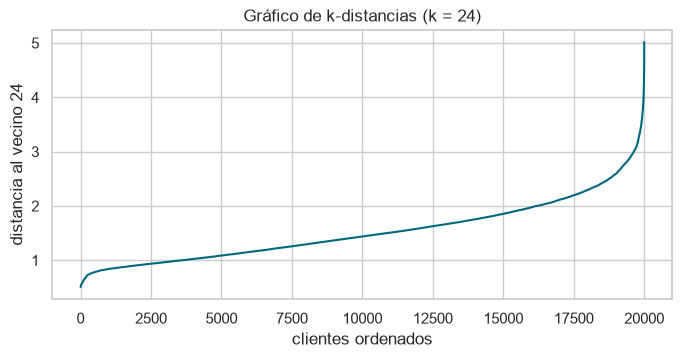

,eps,nº clusters,% ruido,cluster más grande (%)
0,0.500,0,100.000,0.000
1,0.800,15,89.605,6.150
2,1.000,21,65.860,11.830
3,1.300,14,42.890,36.370
4,1.600,10,21.900,64.880
5,2.000,4,7.300,83.890
6,2.500,2,1.615,88.375


In [11]:
MIN_SAMPLES = 2 * X.shape[1]  # regla habitual: 2 × nº de dimensiones
dist_k = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs).kneighbors(Xs)[0][:, -1])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(dist_k, color="#00677F")
ax.set(title=f"Gráfico de k-distancias (k = {MIN_SAMPLES})", xlabel="clientes ordenados", ylabel=f"distancia al vecino {MIN_SAMPLES}")
plt.show()

filas = []
for eps in [0.5, 0.8, 1.0, 1.3, 1.6, 2.0, 2.5]:
    l = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Xs)
    nc = len(set(l)) - (-1 in l)
    filas.append({"eps": eps, "nº clusters": nc, "% ruido": (l == -1).mean() * 100,
                  "cluster más grande (%)": (np.bincount(l[l >= 0]).max() / len(l) * 100) if nc else 0})
pd.DataFrame(filas)

**No existe un `eps` que dé una segmentación útil:**
- con `eps` pequeño, entre el 66 % y el 100 % de los clientes es "ruido";
- con `eps` grande, un único cluster absorbe al 65-84 %;
- en ningún caso aparecen ~6 grupos equilibrados.

Además, el gráfico de k-distancias no tiene un "codo" claro. Es lo esperable: DBSCAN busca zonas densas **separadas por
vacíos**, y nuestros clientes forman un **continuo** sin vacíos (Reto 3). Como **no se puede fijar k = 6**, DBSCAN no
entra en la tabla comparativa; queda documentado como algoritmo **no adecuado** para estos datos.

## 5. Tabla y gráfico comparativo

In [12]:
tabla = pd.DataFrame(resultados).set_index("algoritmo")
tabla

,nº clusters,silhouette,Calinski-Harabasz,Davies-Bouldin,cluster más grande (%),cluster más pequeño (%),tiempo (s),notas
algoritmo,,,,,,,,
K-Means,6,0.136,"2,205.665",1.892,27.067,8.747,5.078,"n_init=50, todos los clientes"
GMM (estándar),6,0.114,"1,728.001",2.619,46.054,8.776,6.955,"covarianza completa, reg_covar=1e-6"
GMM (regularizado),6,0.166,"1,924.937",1.838,52.349,6.180,NaN,"reg_covar=0,3 (mejor silhouette de la tabla)"
Aglomerativo (Ward),6,0.147,"1,815.860",1.992,38.725,7.666,26.725,"entrenado con 20.000, extendido con 15 vecinos"
Aglomerativo (average),6,0.205,225.596,1.248,97.450,0.005,11.098,degenerado: solo como ejemplo


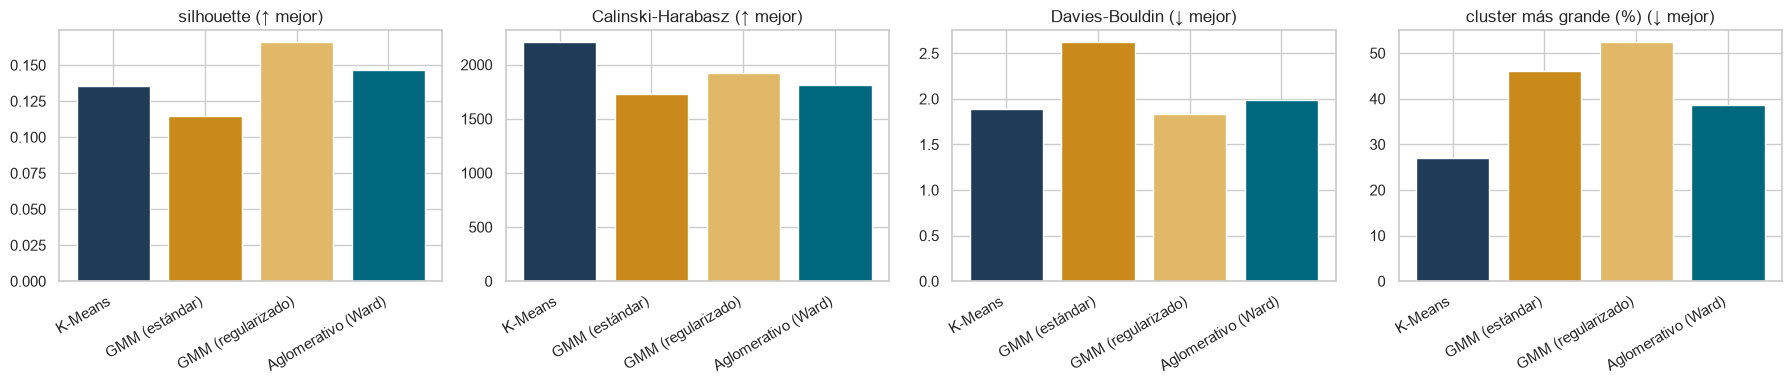

In [13]:
comp = tabla.drop(index="Aglomerativo (average)")
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
colores = ["#1f3b57", "#c98a1b", "#e0b867", "#00677F"]
for ax, (col, mejor) in zip(axes, [("silhouette", "↑"), ("Calinski-Harabasz", "↑"), ("Davies-Bouldin", "↓"),
                                   ("cluster más grande (%)", "↓")]):
    ax.bar(comp.index, comp[col], color=colores)
    ax.set_title(f"{col} ({mejor} mejor)")
    ax.tick_params(axis="x", rotation=30)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
plt.tight_layout()
plt.show()

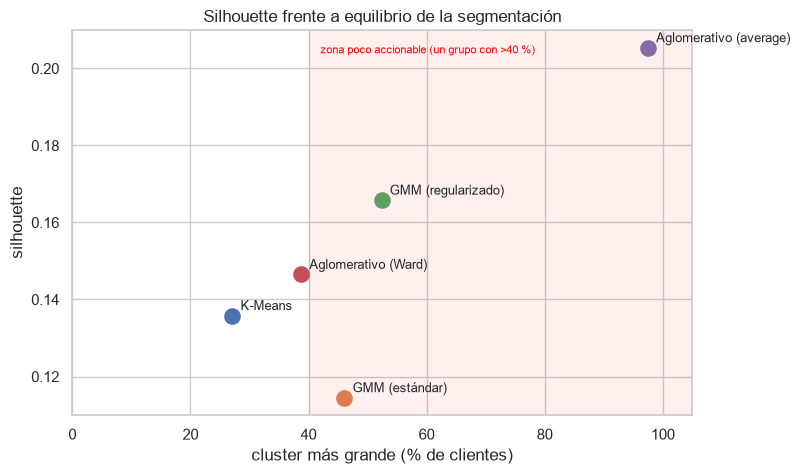

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
for nombre, fila in tabla.iterrows():
    ax.scatter(fila["cluster más grande (%)"], fila["silhouette"], s=120)
    ax.annotate(nombre, (fila["cluster más grande (%)"], fila["silhouette"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set(title="Silhouette frente a equilibrio de la segmentación", xlabel="cluster más grande (% de clientes)",
       ylabel="silhouette", xlim=(0, 105))
ax.axvspan(40, 105, color="red", alpha=.06)
ax.text(42, ax.get_ylim()[1] - .006, "zona poco accionable (un grupo con >40 %)", color="red", fontsize=8)
plt.show()

**Lectura de las métricas:**
- **K-Means** tiene el mejor **Calinski-Harabasz** y el reparto **más equilibrado** (el cluster más grande tiene el 27 %).
  En **Davies-Bouldin** solo le supera ligeramente el GMM regularizado (1,84 frente a 1,89).
- GMM regularizado y Ward obtienen un **silhouette algo mayor** (≈ +0,01 a +0,03), pero siempre a costa de un **cluster
  enorme** (38-52 %). Es el mismo fenómeno que con k = 4 en el Reto 3: juntar a "los del medio" sube el silhouette porque
  deja aislados a los grupos extremos.
- Las diferencias de silhouette son **pequeñas** (todas entre 0,11 y 0,17) y están dentro de la zona de "estructura
  débil": ningún algoritmo descubre grupos que K-Means no viera.

## 6. ¿Cambian los segmentos entre algoritmos?

### 6.1 Parecido global (ARI)

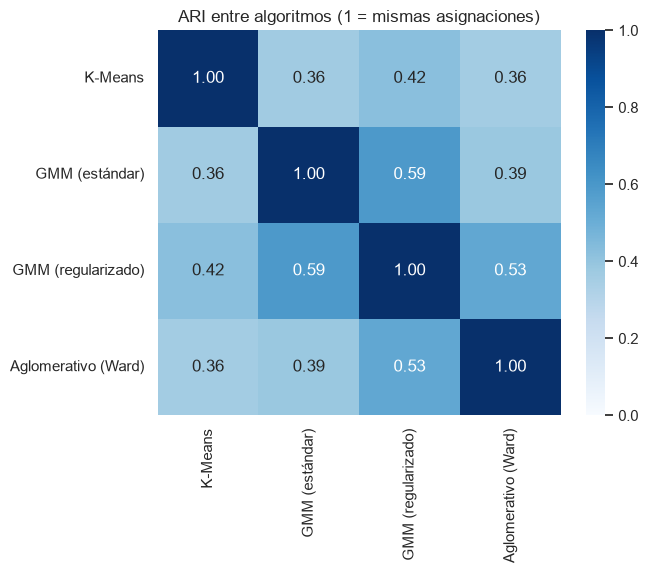

In [15]:
particiones = {"K-Means": km.labels_, "GMM (estándar)": lab_gmm, "GMM (regularizado)": lab_gmm_reg, "Aglomerativo (Ward)": lab_ward}
ari = pd.DataFrame({a: {b: adjusted_rand_score(particiones[a], particiones[b]) for b in particiones} for a in particiones})
plt.figure(figsize=(6.5, 5))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("ARI entre algoritmos (1 = mismas asignaciones)")
plt.show()

El parecido entre algoritmos es **moderado** (ARI ≈ 0,3-0,45): hay segmentos que se mantienen y otros que cambian.
El ARI global no dice **cuáles**, así que lo miramos segmento a segmento.

### 6.2 Segmento a segmento

Los números de cluster de cada algoritmo no se corresponden entre sí (el "2" de Ward no es el "2" de K-Means). Se
emparejan con el **algoritmo húngaro**, que busca la correspondencia que maximiza los clientes coincidentes.

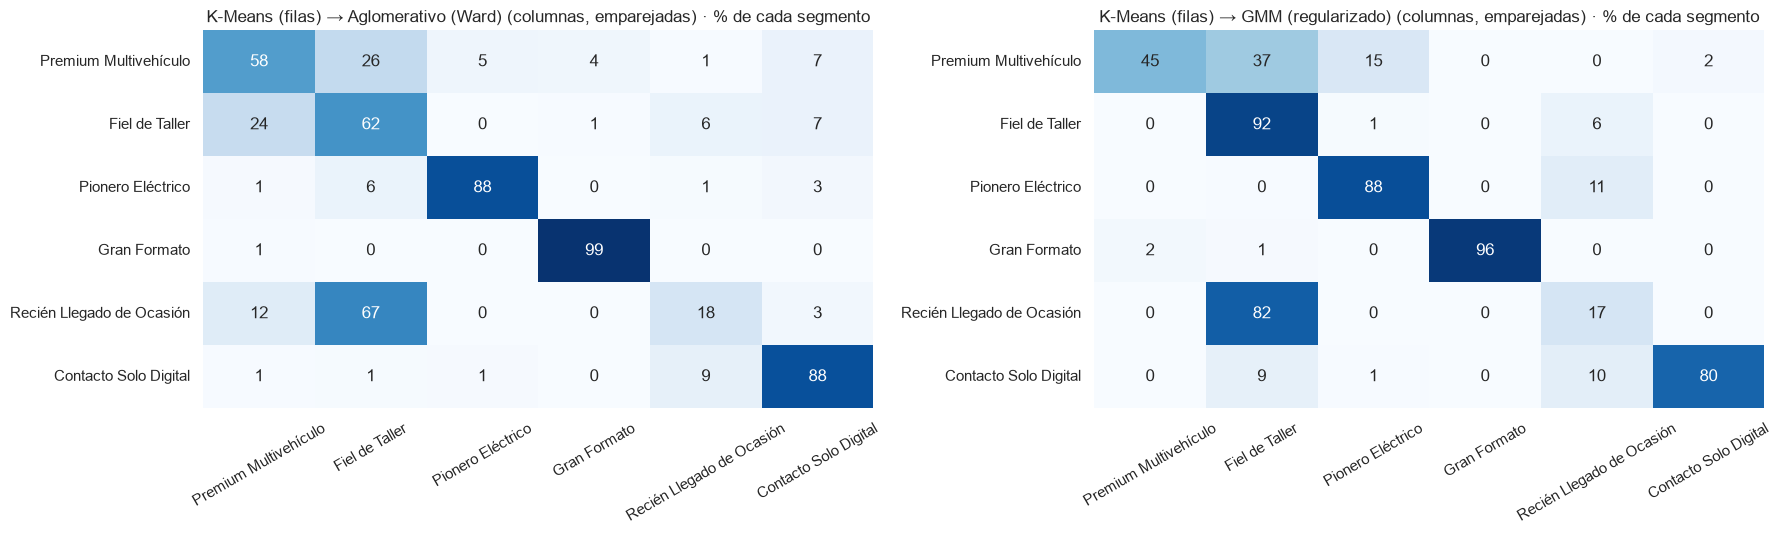

In [16]:
def correspondencia(lab_otro):
    tabla_c = pd.crosstab(seg_km, lab_otro)
    filas_, cols_ = linear_sum_assignment(-tabla_c.to_numpy())
    pareja = {tabla_c.columns[c]: tabla_c.index[f] for f, c in zip(filas_, cols_)}
    pct = pd.crosstab(seg_km, pd.Series(lab_otro).map(pareja).fillna("(sin pareja)"), normalize="index").mul(100)
    return pct.reindex(columns=ORDEN_SEGMENTOS + [c for c in pct.columns if c not in ORDEN_SEGMENTOS])

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
for ax, (nombre, lab) in zip(axes, [("Aglomerativo (Ward)", lab_ward), ("GMM (regularizado)", lab_gmm_reg)]):
    sns.heatmap(correspondencia(lab), annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=ax, cbar=False)
    ax.set(title=f"K-Means (filas) → {nombre} (columnas, emparejadas) · % de cada segmento", xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [17]:
persistencia = pd.DataFrame({
    nombre: pd.Series(np.diag(correspondencia(lab)[ORDEN_SEGMENTOS].loc[ORDEN_SEGMENTOS].to_numpy()), index=ORDEN_SEGMENTOS)
    for nombre, lab in [("GMM (estándar)", lab_gmm), ("GMM (regularizado)", lab_gmm_reg), ("Aglomerativo (Ward)", lab_ward)]
})
persistencia["media"] = persistencia.mean(axis=1)
persistencia.sort_values("media", ascending=False).round(0)

,GMM (estándar),GMM (regularizado),Aglomerativo (Ward),media
Gran Formato,97.000,96.000,99.000,97.000
Pionero Eléctrico,82.000,88.000,88.000,86.000
Fiel de Taller,78.000,92.000,62.000,77.000
Contacto Solo Digital,11.000,80.000,88.000,59.000
Premium Multivehículo,71.000,45.000,58.000,58.000
Recién Llegado de Ocasión,17.000,17.000,18.000,17.000


**Cuidado al leer esta tabla.** El emparejamiento es **uno a uno**: cada cluster del otro algoritmo se asigna a un único
segmento de K-Means. Si un algoritmo **junta dos segmentos** en un cluster grande, ese cluster se empareja con uno de los
dos y el otro parece "desaparecer". Es lo que pasa con Recién Llegado de Ocasión. Por eso medimos también qué parte de
cada segmento acaba en el **cluster más grande** del otro algoritmo:

In [18]:
def en_cluster_mayor(lab):
    mayor = np.bincount(lab).argmax()
    return pd.Series(lab == mayor).groupby(seg_km, observed=True).mean().mul(100).reindex(ORDEN_SEGMENTOS)

fusion = pd.DataFrame({nombre: en_cluster_mayor(lab) for nombre, lab in
                       [("GMM (estándar)", lab_gmm), ("GMM (regularizado)", lab_gmm_reg), ("Aglomerativo (Ward)", lab_ward)]})
fusion.columns = [f"{c} · cluster mayor = {np.bincount(l).max() / len(l):.0%}" for c, l in
                  zip(fusion.columns, [lab_gmm, lab_gmm_reg, lab_ward])]
fusion.round(0)

,GMM (estándar) · cluster mayor = 46%,GMM (regularizado) · cluster mayor = 52%,Aglomerativo (Ward) · cluster mayor = 39%
Premium Multivehículo,0.000,37.000,26.000
Fiel de Taller,78.000,92.000,62.000
Pionero Eléctrico,0.000,0.000,6.000
Gran Formato,0.000,1.000,0.000
Recién Llegado de Ocasión,74.000,82.000,67.000
Contacto Solo Digital,51.000,9.000,1.000


**Lectura:**
- **Robustos**: **Gran Formato** (~97 %) y **Pionero Eléctrico** (~86 %) se reproducen con todos los algoritmos. Están
  definidos por un rasgo muy marcado (furgoneta, electrificado) y cualquier método los encuentra.
- **Contacto Solo Digital**: robusto con Ward y GMM regularizado (80-88 %). Con el GMM estándar se disuelve, porque sus
  componentes degenerados (apartado 2) se forman sobre otros valores exactos.
- **Fiel de Taller y Recién Llegado de Ocasión se fusionan**: los demás algoritmos meten a la mayoría de ambos en su
  **cluster gigante**. Los separa sobre todo el uso del taller, una variable continua, y solo K-Means corta ese continuo
  en dos. Recién Llegado aparece con un 17 % en la tabla anterior no porque se disperse, sino porque su "pareja" se la
  queda Fiel de Taller.
- **Premium Multivehículo** (~58 %) se reparte entre dos grupos, coherente con su heterogeneidad (Reto 3) y con sus
  sub-perfiles (Reto 4).

Esto **no invalida** los segmentos que se fusionan, pero indica que son un **corte dentro de un continuo**, no grupos
naturales. Es una decisión de negocio (Reto 3: separar a toda la base en grupos accionables). Para marketing significa
que la frontera entre Fiel de Taller y Recién Llegado es **gradual**: a los clientes cercanos a ella les encajan
mensajes de ambos.

## 7. Conclusión: ¿qué algoritmo es el más adecuado?

| Criterio | K-Means | GMM | Aglomerativo (Ward) | DBSCAN |
|---|---|---|---|---|
| Admite k = 6 | ✅ | ✅ | ✅ | ❌ |
| Silhouette | 0,14 | 0,11-0,17 (según `reg_covar`) | 0,15 | — |
| Calinski-Harabasz | **2.206** | 1.728-1.925 | 1.816 | — |
| Davies-Bouldin | 1,89 | 1,84-2,62 | 1,99 | — |
| Equilibrio (cluster más grande) | **27 %** | 35-52 % | ~38 % | 65-84 % |
| Estabilidad | **ARI 0,995** entre semillas | Sensible a `reg_covar` y a la semilla (ARI 0,59) | ARI 0,54-0,64 entre muestras | — |
| Usa todos los clientes | ✅ | ✅ | ❌ (muestra de 20.000) | ❌ (muestra) |
| Supuestos adecuados a los datos | ✅ | ❌ (degenera con variables discretas) | ✅ | ❌ (no hay zonas densas separadas) |
| Interpretabilidad | Centroides claros | Medias + covarianzas | Sin centroides propios | — |

**K-Means es el algoritmo más adecuado** para esta segmentación:
1. Ningún algoritmo encuentra una estructura claramente mejor: las diferencias de silhouette son pequeñas y siempre
   vienen de crear un cluster gigante, que es menos útil para marketing.
2. Es el **más estable**, el único que usa **toda la base** sin muestreo y el más **equilibrado**.
3. Sus supuestos encajan con los datos preparados (features escaladas, sin necesidad de forma de campana ni de vacíos
   entre grupos).

**Lo que aporta la comparativa:**
- **Gran Formato** y **Pionero Eléctrico** son segmentos robustos, que aparecen con cualquier método; **Contacto Solo
  Digital** también, salvo con el GMM degenerado.
- **Fiel de Taller** y **Recién Llegado de Ocasión** son un corte útil de un continuo (otros métodos los fusionan), y
  **Premium Multivehículo** es heterogéneo. Sus fronteras deben interpretarse de forma gradual.